# 19 · Step by step: interacting Hamiltonians, doping and quantum phase diagrams

1. Write an interacting model (Hubbard) on a cluster cut from any lattice.
2. Solve it exactly (Lanczos ED) and check against an exact result.
3. Measure correlations, gaps and the spectral function.
4. Dope it: energies and correlations versus filling.
5. Mean-field phase diagram versus U and doping (PM / FM / Néel).
6. A quantum phase transition: the transverse-field Ising chain (order parameter, Binder cumulant, entanglement, central charge).
7. Bosons: Mott lobes of the Bose-Hubbard model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import manybody as MB, phases as PH

## Step 1-2: Hubbard model on a 2×4 periodic cluster; check against the dimer formula first

In [2]:
E = MB.Hubbard(M.chain().finite(2), U=4.0).ground_state(1, 1)[0]
print("dimer:", E, " exact:", (4 - np.sqrt(16 + 16)) / 2)
cluster = M.square().supercell([2, 4])         # 8 sites, periodic
ed = MB.Hubbard(cluster, U=4.0, pbc=True)
print("Hilbert space at half filling:", ed.dimension(4, 4))
E0, psi = ed.ground_state(4, 4)
print("E0 =", E0)

dimer: -0.82842712474619  exact: -0.8284271247461903
Hilbert space at half filling: 4900
E0 = -10.252952955263613


## Step 3: correlations, gaps, spectral function

<S_0 . S_j> = [[ 0.554 -0.083  0.05  -0.083 -0.491  0.06  -0.067  0.06 ]]


total spin S = 0.0   charge gap = 1.6367   spin gap = 0.4201


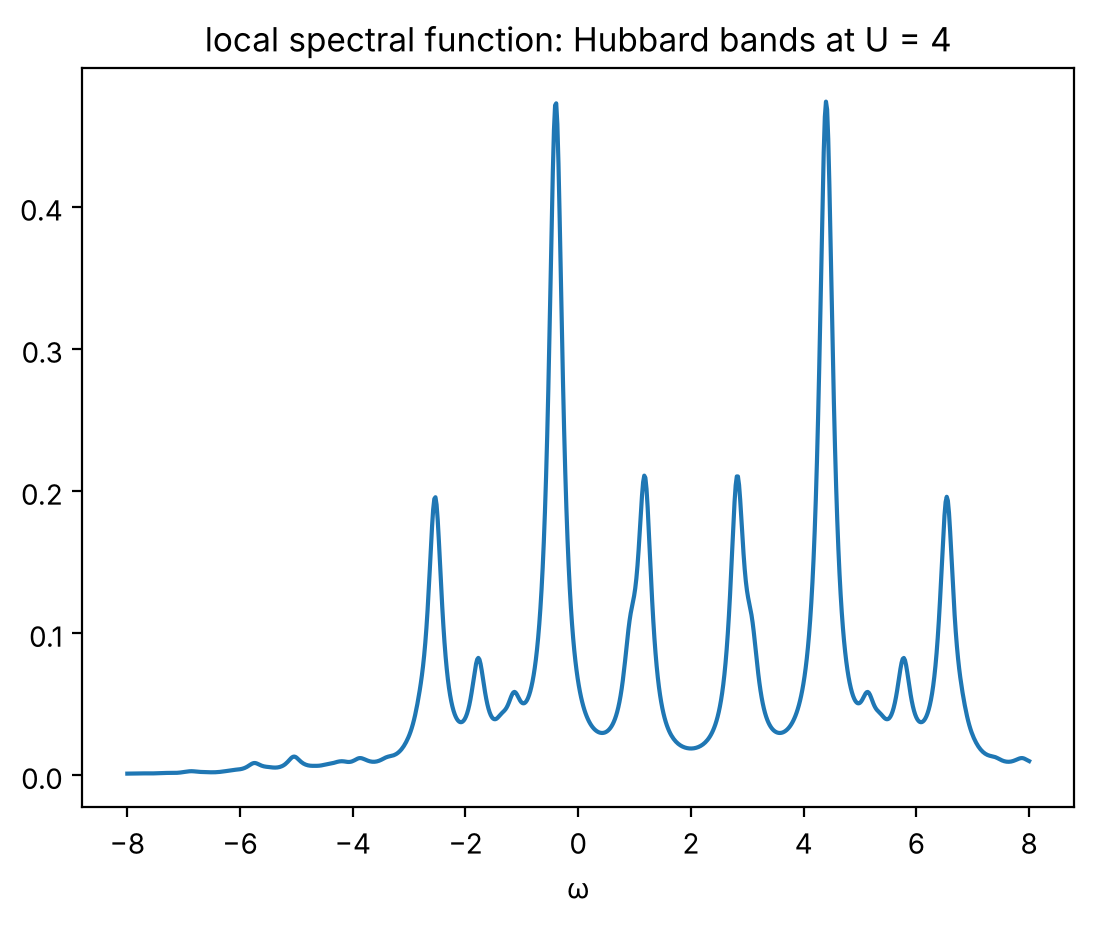

In [3]:
C = np.array([[ed.spin_correlation(psi, 0, j, 4, 4) for j in range(8)]])
print("<S_0 . S_j> =", np.round(C, 3))
print("total spin S =", round(ed.total_spin(psi, 4, 4), 4), "  charge gap =", round(ed.charge_gap(4, 4), 4),
      "  spin gap =", round(ed.spin_gap(4, 4), 4))
w = np.linspace(-8, 8, 800)
A = -ed.greens_function(0, 4, 4, w, eta=0.15).imag / np.pi
plt.plot(w, A); plt.xlabel("ω"); plt.title("local spectral function: Hubbard bands at U = 4");

## Step 4: doping the cluster

In [4]:
Us = [2.0, 4.0, 8.0]
for U in Us:
    ed = MB.Hubbard(cluster, U=U, pbc=True)
    rows = []
    for N in range(2, 9, 2):
        E, sec = ed.ground_state_all_sectors(N, n_jobs=-1)
        rows.append((N, E, sec))
    print(f"U={U}: " + "  ".join(f"N={N}: E={E:.3f} {sec}" for N, E, sec in rows))

U=2.0: N=2: E=-7.801 (1, 1)  N=4: E=-11.395 (2, 2)  N=6: E=-14.033 (3, 3)  N=8: E=-12.705 (4, 4)


U=4.0: N=2: E=-7.671 (1, 1)  N=4: E=-10.991 (2, 2)  N=6: E=-12.555 (3, 3)  N=8: E=-10.253 (4, 4)


U=8.0: N=2: E=-7.518 (1, 1)  N=4: E=-10.498 (2, 2)  N=6: E=-10.627 (3, 3)  N=8: E=-7.127 (4, 4)


## Step 5: mean-field phase diagram versus U and doping
Competing PM / FM / Néel solutions are converged at every point, and the lowest energy wins (as in Hirsch 1985).

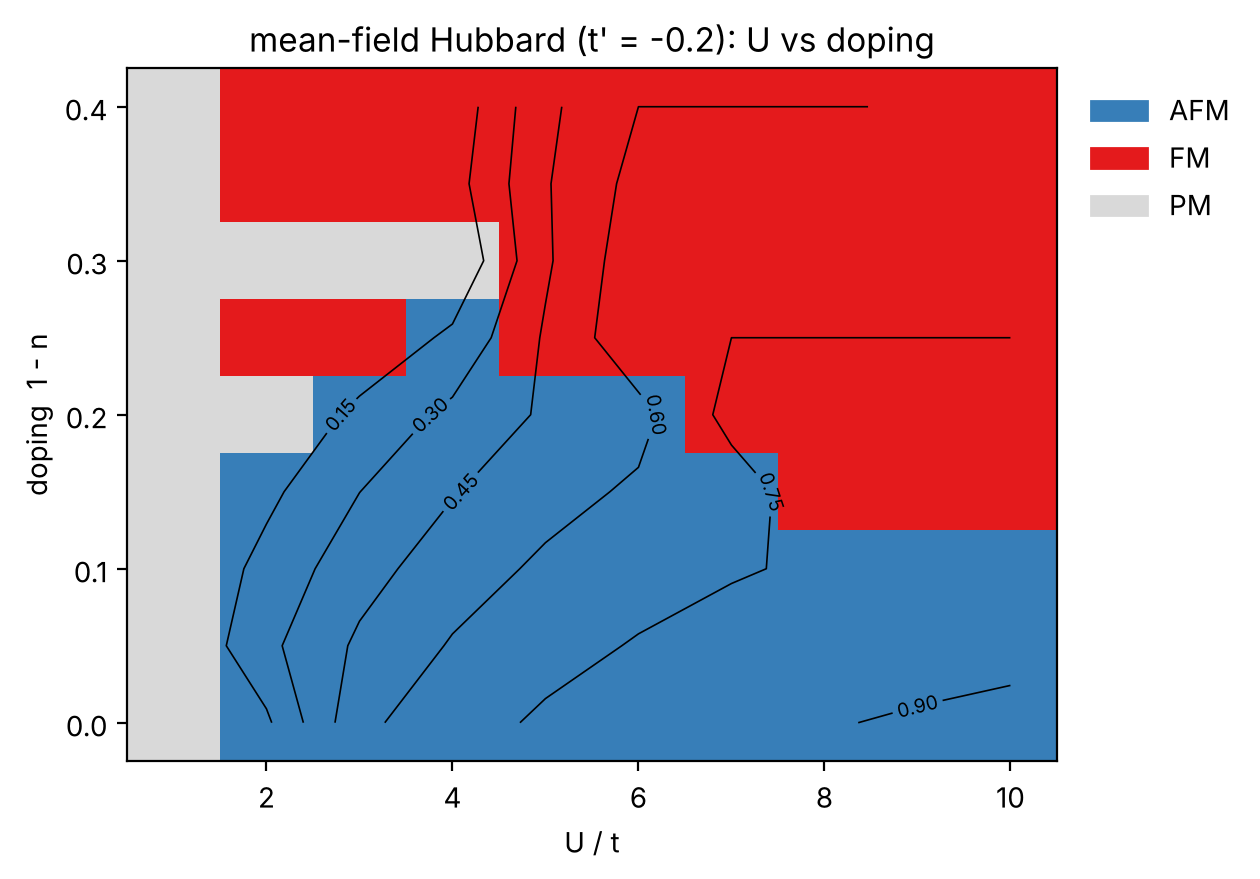

In [5]:
sq2 = M.square(t2=-0.2).make_spinful().supercell([[1, 1], [1, -1]])
pd = PH.hubbard_phase_diagram(sq2, Us=np.linspace(1, 10, 10), fillings=np.linspace(0.5, 0.3, 9), nk=20, n_jobs=-1)
PH.plot_phase_diagram(pd, contour="|m|", title="mean-field Hubbard (t' = -0.2): U vs doping");

## Step 6: a quantum phase transition: the transverse-field Ising chain

Binder crossing h_c ≈ 0.962 (exact: 1)


central charge at h = J: 0.502 (Ising CFT: 1/2)


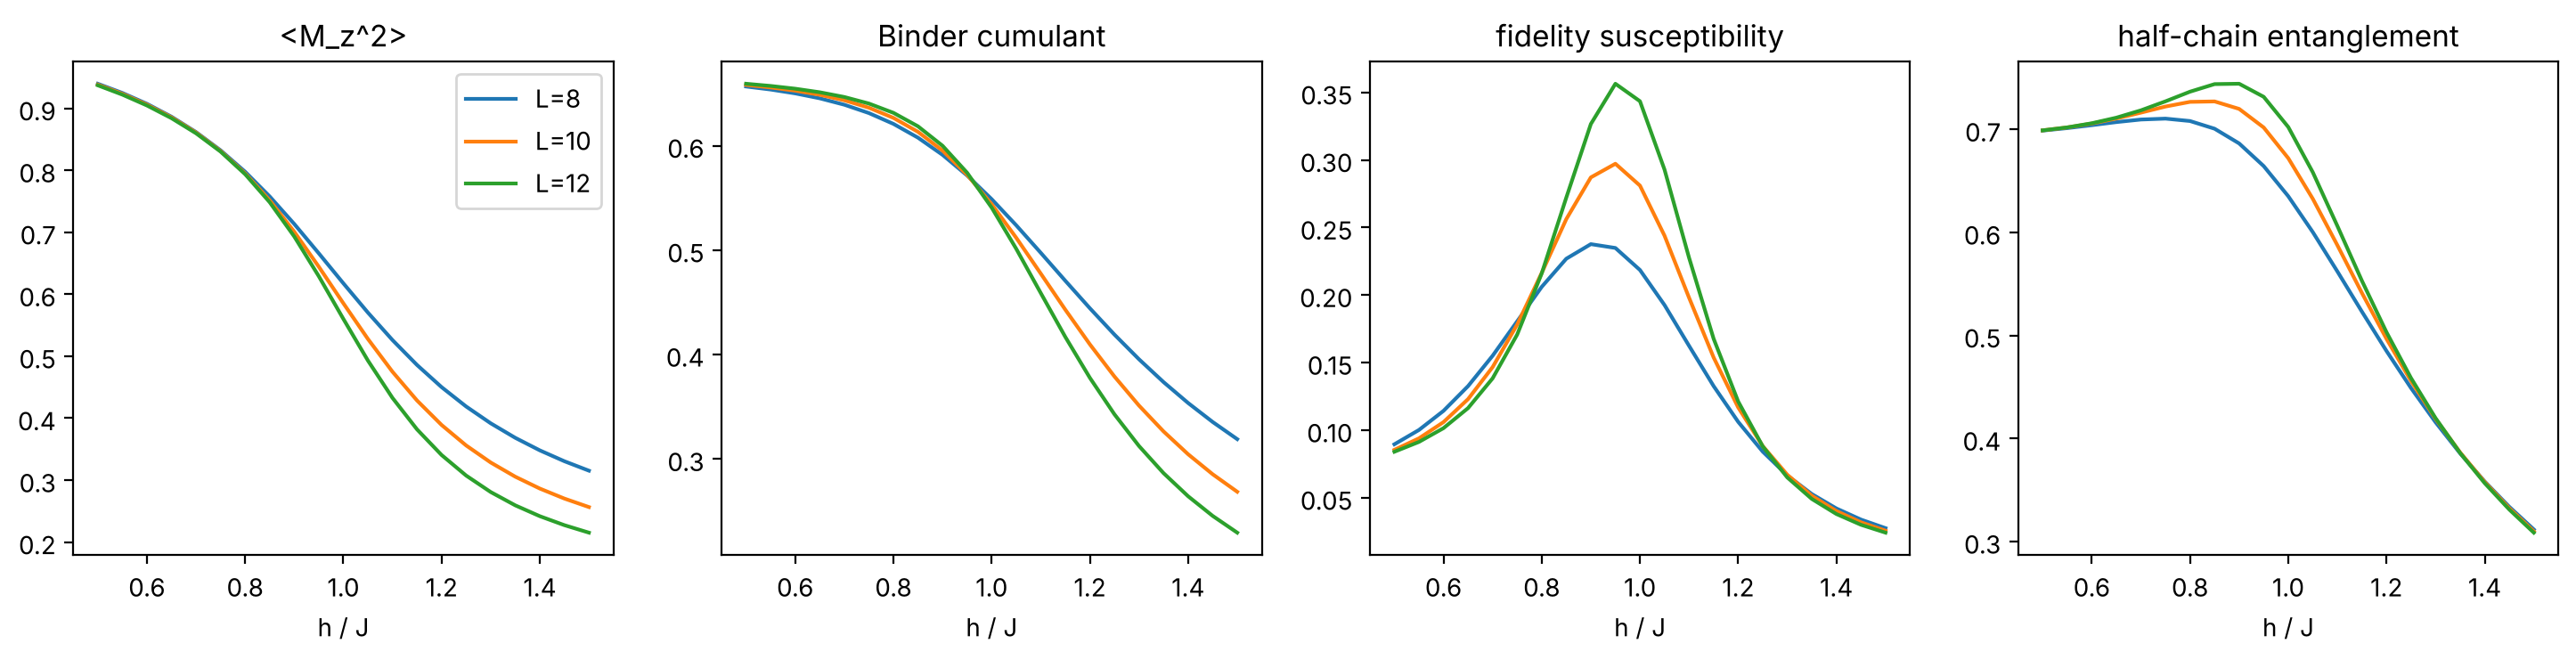

In [6]:
scan = PH.quantum_critical_scan(lambda L, h: MB.PauliModel.transverse_field_ising(L, 1.0, h), "h / J",
                               np.linspace(0.5, 1.5, 21), Ls=(8, 10, 12), n_jobs=-1)
PH.plot_critical_scan(scan)
print("Binder crossing h_c ≈", round(PH.binder_crossing(scan, 0, -1), 3), "(exact: 1)")
psi = MB.PauliModel.transverse_field_ising(16, 1.0, 1.0).ground_state()[1]
print("central charge at h = J:", round(PH.central_charge(psi, 16)[0], 3), "(Ising CFT: 1/2)")

## Step 7: Bose-Hubbard Mott lobes

lobe tip (U/zt)_c = 5.82842712474619 (3 + 2√2)


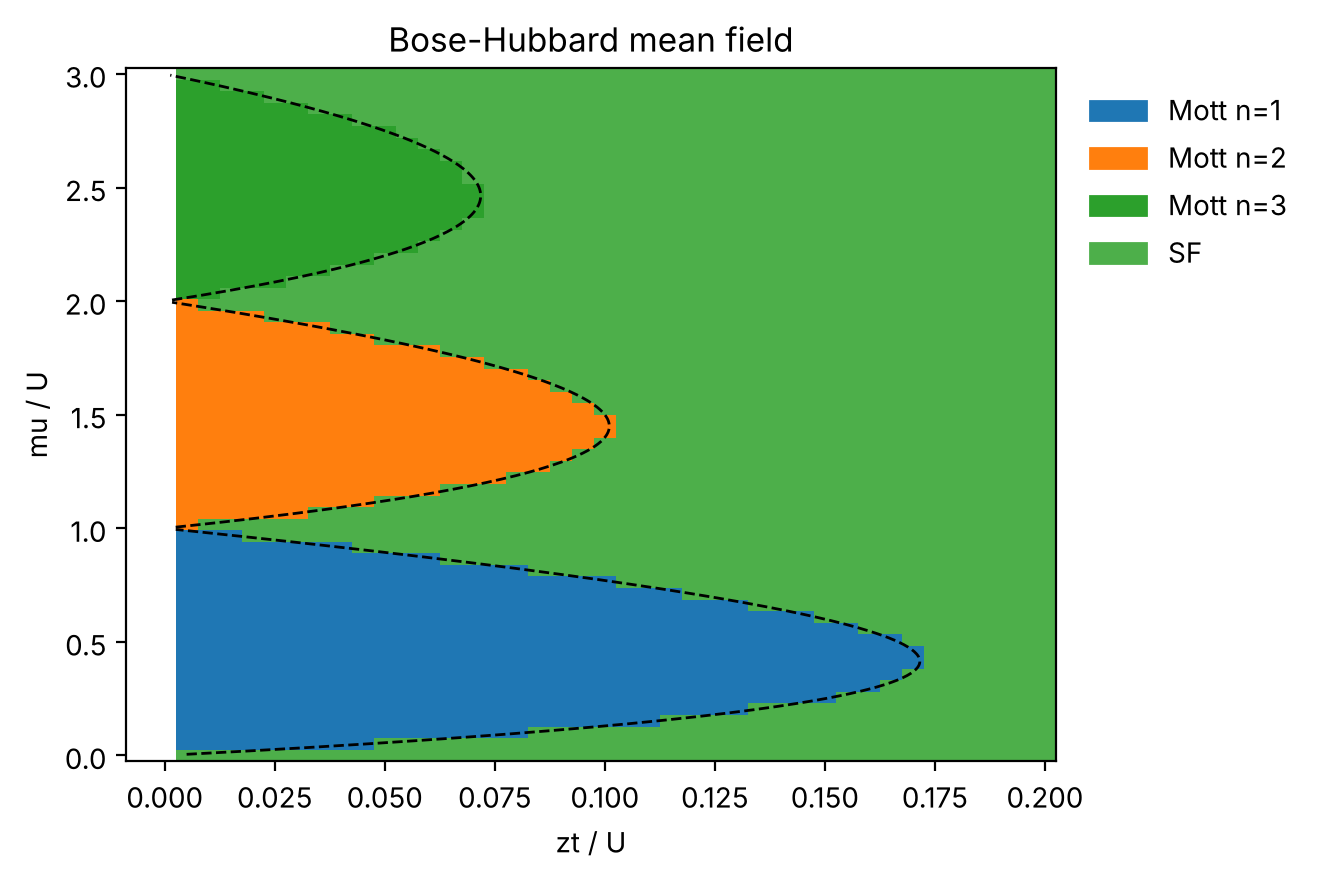

In [7]:
pdb = PH.mott_lobes(np.linspace(0.005, 0.2, 40), np.linspace(0.0, 3.0, 60), n_jobs=-1)
ax = PH.plot_phase_diagram(pdb, title="Bose-Hubbard mean field")
for n in (1, 2, 3):
    mu = np.linspace(n - 1, n, 200)[1:-1]
    ax.plot(MB.mott_lobe_boundary(n, 1.0, mu), mu, "k--", lw=1)
print("lobe tip (U/zt)_c =", 1 / MB.mott_lobe_boundary(1), "(3 + 2√2)");

## Exercises
1. Add a nearest-neighbour V to the cluster (`Hubbard(..., V=1.0)`) and look for charge order.
2. Build a two-orbital Kanamori cluster (`atoms=[[0, 1], ...]`) and find the high-spin/low-spin transition versus J.
3. Repeat Step 6 for the XXZ chain (`SpinModel.chain(L, Delta=...)`).

---
## Quiz 19: Interacting Hamiltonians and phase diagrams

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [8]:
quiz = hf.Quiz(19)
quiz.interactive()

In [9]:
quiz.show()

=== Quiz 19: Interacting Hamiltonians, doping and quantum phase diagrams ===

Q1. Exact diagonalisation is limited by
   (a) the k-mesh
   (b) the exponential growth of the Hilbert space
   (c) the DOS
   (d) the lattice constant

Q2. Conserved N_up and N_dn let ED
   (a) block-diagonalise H into sectors
   (b) use k-points
   (c) skip interactions
   (d) avoid Lanczos

Q3. Lanczos is efficient because
   (a) it needs only matrix-vector products to converge extremal eigenvalues
   (b) it needs no memory
   (c) it is exact always
   (d) it diagonalises fully

Q4. The Hubbard dimer ground-state energy is
   (a) 0
   (b) -2t
   (c) U
   (d) (U - sqrt(U^2 + 16 t^2))/2

Q5. At large U the singlet-triplet splitting of the dimer approaches
   (a) J = 4 t^2 / U (superexchange)
   (b) U
   (c) t
   (d) 0

Q6. The charge gap is
   (a) the spin gap
   (b) E(N) - E(0)
   (c) E(N+1) + E(N-1) - 2E(N)
   (d) U

Q7. The local spectral function is computed by
   (a) Boltzmann
   (b) KPM only
   (c) Lan

In [10]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0